<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Using device: cpu
Merged data shape: (763, 49)
Duplicate patient rows: 0

Predictors: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
Target distribution:
HPV
0    191
1    141
Name: count, dtype: int64

Training samples:
HPV
0    123
1     92
Name: count, dtype: int64

Validation samples:
HPV
0    29
1    21
Name: count, dtype: int64

Test samples:
HPV
0    39
1    28
Name: count, dtype: int64

Original predictors: 6
Encoded input features: 19
CNN input shape: (215, 1, 19)

CNN architecture:
HPVCNN(
  (conv1): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=304, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=2, bias=True)
)
Epoch 50, Train=0.6785, Val=0.6842, ROC AUC=0.7184, PR AUC=0.6223, BA=0.5197
Epoch 100, T

,Model,Checkpoint_Selection,Selected_Epoch,Test_Loss,N_Train,N_Validation,N_Test,Original_Predictor_Count,Encoded_Feature_Count,ROC_AUC,PR_AUC,BA,Accuracy,F1,TN,FP,FN,TP
0,CNN,Best_Validation_Loss,428,0.553725,215,50,67,6,19,0.790293,0.762303,0.708791,0.731343,0.640000,33,6,12,16
1,CNN,Best_Validation_BA,220,0.597328,215,50,67,6,19,0.775641,0.692400,0.759615,0.761194,0.724138,30,9,7,21
2,CNN,Best_Validation_ROC_AUC,381,0.559056,215,50,67,6,19,0.791209,0.744212,0.713828,0.731343,0.653846,32,7,11,17
3,CNN,Best_Validation_PR_AUC,381,0.559056,215,50,67,6,19,0.791209,0.744212,0.713828,0.731343,0.653846,32,7,11,17


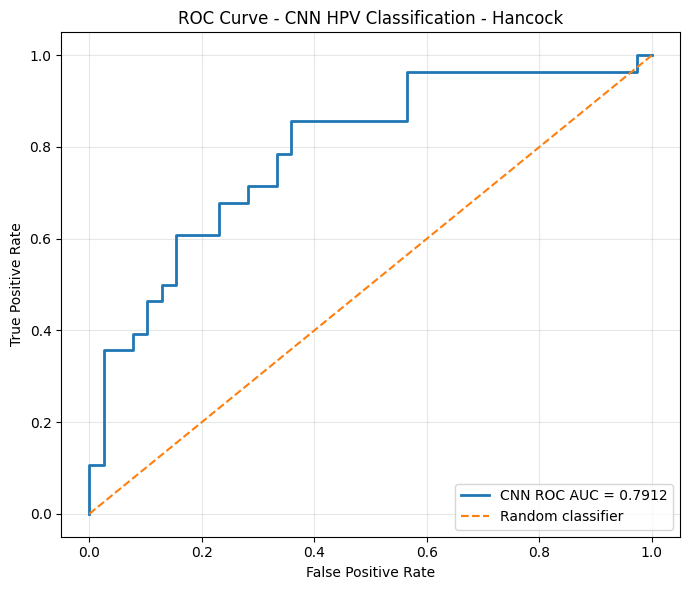

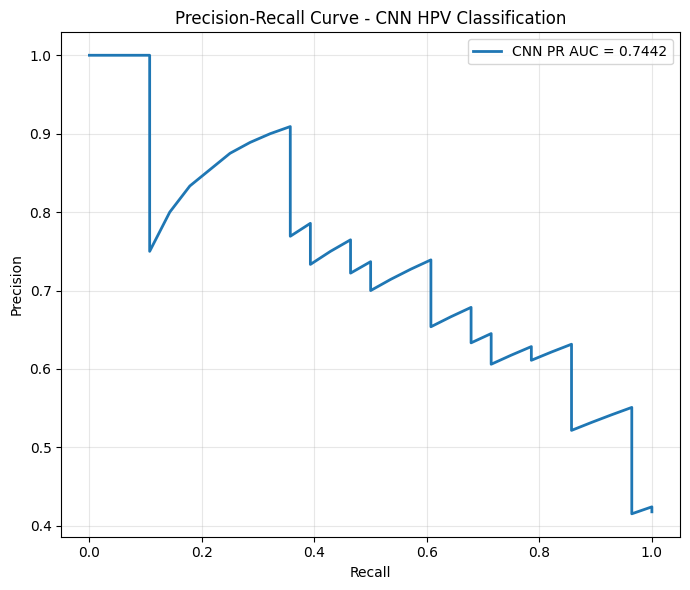


CNN42_HANCOCK SUMMARY
Architecture : Conv1D-16-FC32-FC16-2
Original Predictors : 6
Encoded Input Features : 19
Learning Rate : 0.0001
Optimiser : Adam
Class Weights : Automatic from training set
Encoding : OneHotEncoder
SMOTE : No
Split : Stratified 65/15/20
Preprocessing : Train-only
Scaling : StandardScaler fit on training set
Epochs : 500
Best Validation Loss Epoch : 428
Best Validation BA Epoch : 220
Best Validation ROC AUC Epoch : 381
Best Validation PR AUC Epoch : 381
Training Patients : 215
Validation Patients : 50
Test Patients : 67
Seed : 42
CSV Output Folder : /content/drive/MyDrive/CNN_results


In [1]:

# ========================================
# CNN42_HANCOCK
# ========================================

# 1. IMPORT LIBRARIES AND SET RANDOM SEEDS

from google.colab import drive
drive.mount('/content/drive')

import os
import json
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix,
    balanced_accuracy_score, roc_auc_score,
    average_precision_score, accuracy_score,
    f1_score, precision_recall_curve, roc_curve
)


def seed_everything(seed=42):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEED = 42
seed_everything(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)


# 2. LOAD AND MERGE DATA

with open('/content/drive/MyDrive/clinical_data.json') as f:
    clinical = pd.DataFrame(json.load(f))

with open('/content/drive/MyDrive/pathological_data.json') as f:
    pathology = pd.DataFrame(json.load(f))

df = clinical.merge(
    pathology, on='patient_id', how='inner',
    suffixes=('', '_path')
)

print("Merged data shape:", df.shape)
print("Duplicate patient rows:", df['patient_id'].duplicated().sum())


# 3. SELECT TARGET AND SIX PREDICTORS

target_col = 'hpv_association_p16'

df[target_col] = df[target_col].astype(str).str.strip().str.lower()
df = df[df[target_col].isin(['positive', 'negative'])].copy()
df['HPV'] = df[target_col].map({'negative': 0, 'positive': 1})

features = [
    'age_at_initial_diagnosis',
    'sex',
    'smoking_status',
    'primary_tumor_site',
    'primarily_metastasis',
    'pN_stage'
]

# Handle common alternative names for pN stage
if 'pN_stage' not in df.columns:
    alternatives = [
        'pathological_N_stage', 'pathologic_N_stage',
        'pathological_n_stage', 'pN'
    ]
    matched = next(
        (col for col in alternatives if col in df.columns),
        None
    )
    if matched is not None:
        df = df.rename(columns={matched: 'pN_stage'})

missing_cols = [col for col in features if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing predictors: {missing_cols}")

df = df[['patient_id'] + features + ['HPV']].copy()
df = df.dropna(subset=['HPV'])
df = df.drop_duplicates(subset=['patient_id'], keep='first')
df['HPV'] = df['HPV'].astype(int)

cat_cols = [
    'sex', 'smoking_status', 'primary_tumor_site',
    'primarily_metastasis', 'pN_stage'
]
num_cols = ['age_at_initial_diagnosis']

for col in cat_cols:
    df[col] = df[col].apply(
        lambda x: str(x).strip() if pd.notna(x) else np.nan
    )

df['age_at_initial_diagnosis'] = pd.to_numeric(
    df['age_at_initial_diagnosis'], errors='coerce'
)

X = df[features].copy()
y = df['HPV'].copy()
patient_ids = df['patient_id'].copy()

print("\nPredictors:", features)
print("Target distribution:")
print(y.value_counts().sort_index())


# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
#    65% TRAIN / 15% VALIDATION / 20% TEST

(
    X_train_val, X_test,
    y_train_val, y_test,
    ids_train_val, ids_test
) = train_test_split(
    X, y, patient_ids,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

(
    X_train, X_val,
    y_train, y_val,
    ids_train, ids_val
) = train_test_split(
    X_train_val, y_train_val, ids_train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=y_train_val
)

assert set(ids_train).isdisjoint(set(ids_val))
assert set(ids_train).isdisjoint(set(ids_test))
assert set(ids_val).isdisjoint(set(ids_test))

print("\nTraining samples:")
print(y_train.value_counts().sort_index())
print("\nValidation samples:")
print(y_val.value_counts().sort_index())
print("\nTest samples:")
print(y_test.value_counts().sort_index())


# 5. PREPROCESS FEATURES
#    Fit preprocessing on TRAIN ONLY

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

if hasattr(X_train, 'toarray'):
    X_train = X_train.toarray()
if hasattr(X_val, 'toarray'):
    X_val = X_val.toarray()
if hasattr(X_test, 'toarray'):
    X_test = X_test.toarray()

X_train = np.asarray(X_train, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

n_features = X_train.shape[1]

# CNN input shape: samples, channels, encoded features
X_train = torch.tensor(X_train).unsqueeze(1).to(device)
X_val = torch.tensor(X_val).unsqueeze(1).to(device)
X_test = torch.tensor(X_test).unsqueeze(1).to(device)

y_train = torch.tensor(y_train_np, dtype=torch.long).to(device)
y_val = torch.tensor(y_val_np, dtype=torch.long).to(device)
y_test = torch.tensor(y_test_np, dtype=torch.long).to(device)

print("\nOriginal predictors:", len(features))
print("Encoded input features:", n_features)
print("CNN input shape:", tuple(X_train.shape))


# 6. DEFINE CNN ARCHITECTURE

class HPVCNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.conv1 = nn.Conv1d(
            in_channels=1, out_channels=16,
            kernel_size=3, padding=1
        )
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * n_features, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 2)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)


model = HPVCNN(n_features).to(device)
print("\nCNN architecture:")
print(model)


# 7. LOSS FUNCTION AND OPTIMIZER

class_counts = np.bincount(y_train_np, minlength=2)
if np.any(class_counts == 0):
    raise ValueError("Training split is missing a target class.")

weights = len(y_train_np) / (2 * class_counts)
class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

epochs = 500


# 8. METRIC HELPER

def calculate_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)

    auc = np.nan
    pr_auc = np.nan
    if len(np.unique(y_true)) == 2:
        auc = roc_auc_score(y_true, y_prob)
        pr_auc = average_precision_score(y_true, y_prob)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        'ROC_AUC': auc,
        'PR_AUC': pr_auc,
        'BA': balanced_accuracy_score(y_true, y_pred),
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'TN': int(tn), 'FP': int(fp),
        'FN': int(fn), 'TP': int(tp)
    }


# 9. TRAIN CNN
#    Select checkpoints using VALIDATION metrics only

best_val_loss = float('inf')
best_val_ba = -float('inf')
best_val_auc = -float('inf')
best_val_pr_auc = -float('inf')

best_loss_state = None
best_ba_state = None
best_auc_state = None
best_pr_state = None

best_loss_epoch = 0
best_ba_epoch = 0
best_auc_epoch = 0
best_pr_epoch = 0
history = []

for epoch in range(epochs):
    model.train()
    outputs = model(X_train)
    train_loss = criterion(outputs, y_train)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = criterion(val_outputs, y_val).item()
        val_prob = torch.softmax(val_outputs, dim=1)[:, 1].cpu().numpy()

        train_prob = torch.softmax(
            outputs.detach(), dim=1
        )[:, 1].cpu().numpy()

    train_metrics = calculate_metrics(y_train_np, train_prob)
    val_metrics = calculate_metrics(y_val_np, val_prob)

    history.append({
        'Epoch': epoch + 1,
        'Train_Loss': train_loss.item(),
        'Validation_Loss': val_loss,
        'Train_ROC_AUC': train_metrics['ROC_AUC'],
        'Train_PR_AUC': train_metrics['PR_AUC'],
        'Train_BA': train_metrics['BA'],
        'Validation_ROC_AUC': val_metrics['ROC_AUC'],
        'Validation_PR_AUC': val_metrics['PR_AUC'],
        'Validation_BA': val_metrics['BA']
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_loss_epoch = epoch + 1
        best_loss_state = copy.deepcopy(model.state_dict())

    if val_metrics['BA'] > best_val_ba:
        best_val_ba = val_metrics['BA']
        best_ba_epoch = epoch + 1
        best_ba_state = copy.deepcopy(model.state_dict())

    if (
        not np.isnan(val_metrics['ROC_AUC'])
        and val_metrics['ROC_AUC'] > best_val_auc
    ):
        best_val_auc = val_metrics['ROC_AUC']
        best_auc_epoch = epoch + 1
        best_auc_state = copy.deepcopy(model.state_dict())

    if (
        not np.isnan(val_metrics['PR_AUC'])
        and val_metrics['PR_AUC'] > best_val_pr_auc
    ):
        best_val_pr_auc = val_metrics['PR_AUC']
        best_pr_epoch = epoch + 1
        best_pr_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}, "
            f"Train={train_loss.item():.4f}, "
            f"Val={val_loss:.4f}, "
            f"ROC AUC={val_metrics['ROC_AUC']:.4f}, "
            f"PR AUC={val_metrics['PR_AUC']:.4f}, "
            f"BA={val_metrics['BA']:.4f}"
        )

print("\nTraining complete.")
print("Best validation loss epoch:", best_loss_epoch)
print("Best validation BA epoch:", best_ba_epoch)
print("Best validation ROC AUC epoch:", best_auc_epoch)
print("Best validation PR AUC epoch:", best_pr_epoch)


# 10. SAVE EPOCH HISTORY TO CSV

output_dir = '/content/drive/MyDrive/CNN_results'
os.makedirs(output_dir, exist_ok=True)

history_path = os.path.join(
    output_dir, 'CNN_epoch_history.csv'
)
pd.DataFrame(history).to_csv(history_path, index=False)
print("Saved:", history_path)


# 11. EVALUATE CHECKPOINTS ON TEST SET

checkpoints = {
    'Best_Validation_Loss': (best_loss_state, best_loss_epoch),
    'Best_Validation_BA': (best_ba_state, best_ba_epoch),
    'Best_Validation_ROC_AUC': (best_auc_state, best_auc_epoch),
    'Best_Validation_PR_AUC': (best_pr_state, best_pr_epoch)
}

results = []
test_predictions = []

for selection, (state, selected_epoch) in checkpoints.items():
    if state is None:
        continue

    model.load_state_dict(state)
    model.eval()

    with torch.no_grad():
        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test).item()
        test_prob = torch.softmax(
            test_outputs, dim=1
        )[:, 1].cpu().numpy()

    metrics = calculate_metrics(y_test_np, test_prob)

    results.append({
        'Model': 'CNN',
        'Checkpoint_Selection': selection,
        'Selected_Epoch': selected_epoch,
        'Test_Loss': test_loss,
        'N_Train': len(y_train_np),
        'N_Validation': len(y_val_np),
        'N_Test': len(y_test_np),
        'Original_Predictor_Count': len(features),
        'Encoded_Feature_Count': n_features,
        **metrics
    })

    for patient_id, true_label, probability in zip(
        ids_test.to_numpy(), y_test_np, test_prob
    ):
        test_predictions.append({
            'Model': 'CNN',
            'Checkpoint_Selection': selection,
            'Selected_Epoch': selected_epoch,
            'patient_id': patient_id,
            'y_true': int(true_label),
            'y_prob_HPV_positive': float(probability),
            'y_pred_threshold_0.5': int(probability >= 0.5)
        })

    print(f"\n{selection} (epoch {selected_epoch})")
    print(f"ROC AUC: {metrics['ROC_AUC']:.4f}")
    print(f"PR AUC:  {metrics['PR_AUC']:.4f}")
    print(f"BA:      {metrics['BA']:.4f}")
    print("Confusion Matrix:")
    print(np.array([
        [metrics['TN'], metrics['FP']],
        [metrics['FN'], metrics['TP']]
    ]))


# 12. SAVE TEST RESULTS AND PREDICTIONS TO CSV

results_path = os.path.join(output_dir, 'CNN_results.csv')
predictions_path = os.path.join(
    output_dir, 'CNN_test_predictions.csv'
)

results_df = pd.DataFrame(results)
results_df.to_csv(results_path, index=False)

pd.DataFrame(test_predictions).to_csv(
    predictions_path, index=False
)

print("\nSaved:", results_path)
print("Saved:", predictions_path)
print("\nTest results:")
display(results_df)


# 13. PLOT ROC AND PRECISION-RECALL CURVES
#     Using the best validation ROC AUC checkpoint

if best_auc_state is not None:
    model.load_state_dict(best_auc_state)
    model.eval()

    with torch.no_grad():
        outputs = model(X_test)
        y_score = torch.softmax(
            outputs, dim=1
        )[:, 1].cpu().numpy()

    fpr, tpr, _ = roc_curve(y_test_np, y_score)
    auc = roc_auc_score(y_test_np, y_score)

    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, linewidth=2, label=f'CNN ROC AUC = {auc:.4f}')
    plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - CNN HPV Classification - Hancock')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    precision, recall, _ = precision_recall_curve(
        y_test_np, y_score
    )
    pr_auc = average_precision_score(y_test_np, y_score)

    plt.figure(figsize=(7, 6))
    plt.plot(
        recall, precision, linewidth=2,
        label=f'CNN PR AUC = {pr_auc:.4f}'
    )
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve - CNN HPV Classification')
    plt.legend(loc='best')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# 14. CNN42_HANCOCK SUMMARY

print("\n====================================")
print("CNN42_HANCOCK SUMMARY")
print("====================================")
print("Architecture : Conv1D-16-FC32-FC16-2")
print("Original Predictors :", len(features))
print("Encoded Input Features :", n_features)
print("Learning Rate : 0.0001")
print("Optimiser : Adam")
print("Class Weights : Automatic from training set")
print("Encoding : OneHotEncoder")
print("SMOTE : No")
print("Split : Stratified 65/15/20")
print("Preprocessing : Train-only")
print("Scaling : StandardScaler fit on training set")
print("Epochs :", epochs)
print("Best Validation Loss Epoch :", best_loss_epoch)
print("Best Validation BA Epoch :", best_ba_epoch)
print("Best Validation ROC AUC Epoch :", best_auc_epoch)
print("Best Validation PR AUC Epoch :", best_pr_epoch)
print("Training Patients :", len(y_train_np))
print("Validation Patients :", len(y_val_np))
print("Test Patients :", len(y_test_np))
print("Seed :", SEED)
print("CSV Output Folder :", output_dir)
